In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("student_career_success_dataset.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 50000
Columns: 29


In [3]:
print("Column Names:")
for i, column in enumerate(df.columns, 1):
    print(i, "→", column)

Column Names:
1 → Student_ID
2 → Age
3 → Gender
4 → University_Year
5 → Major
6 → Attendance_Percentage
7 → Study_Hours_Per_Week
8 → CGPA
9 → Academic_Performance
10 → Programming_Skill
11 → Projects_Completed
12 → Certifications
13 → Hackathons
14 → GitHub_Profile
15 → Internships
16 → Leadership_Experience
17 → LinkedIn_Profile
18 → Resume_Score
19 → Communication_Skills
20 → Teamwork
21 → Problem_Solving
22 → English_Proficiency
23 → Interview_Score
24 → Employability_Score
25 → Placement_Status
26 → Company_Tier
27 → Career_Field
28 → Placement_Mode
29 → Starting_Salary_USD


In [4]:
df.head()

,Student_ID,Age,Gender,University_Year,Major,Attendance_Percentage,Study_Hours_Per_Week,CGPA,Academic_Performance,Programming_Skill,...,Teamwork,Problem_Solving,English_Proficiency,Interview_Score,Employability_Score,Placement_Status,Company_Tier,Career_Field,Placement_Mode,Starting_Salary_USD
0,ST000001,22,Male,Sophomore,Computer Science,86,21,3.28,Good,9,...,7,8,Advanced,72,231.70,Placed,Tier 1,Backend Developer,Campus Placement,72082
1,ST000002,20,Female,Freshman,Computer Science,64,18,2.53,Poor,6,...,6,5,Basic,59,157.45,Not Placed,No Company,Not Placed,Not Applicable,0
2,ST000003,23,Male,Senior,Information Technology,75,19,2.83,Average,8,...,8,7,Advanced,76,203.45,Placed,Tier 1,IT Support Engineer,Campus Placement,94898
3,ST000004,23,Female,Senior,Information Technology,80,19,2.80,Average,5,...,6,6,Intermediate,67,171.50,Not Placed,No Company,Not Placed,Not Applicable,0
4,ST000005,23,Female,Senior,Software Engineering,73,19,2.93,Average,9,...,8,9,Advanced,82,225.45,Placed,Tier 1,Software Engineer,Internship Conversion,85256


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             50000 non-null  object 
 1   Age                    50000 non-null  int64  
 2   Gender                 50000 non-null  object 
 3   University_Year        50000 non-null  object 
 4   Major                  50000 non-null  object 
 5   Attendance_Percentage  50000 non-null  int64  
 6   Study_Hours_Per_Week   50000 non-null  int64  
 7   CGPA                   50000 non-null  float64
 8   Academic_Performance   50000 non-null  object 
 9   Programming_Skill      50000 non-null  int64  
 10  Projects_Completed     50000 non-null  int64  
 11  Certifications         50000 non-null  int64  
 12  Hackathons             50000 non-null  int64  
 13  GitHub_Profile         50000 non-null  object 
 14  Internships            50000 non-null  int64  
 15  Le

In [6]:
df.describe()

,Age,Attendance_Percentage,Study_Hours_Per_Week,CGPA,Programming_Skill,Projects_Completed,Certifications,Hackathons,Internships,Resume_Score,Communication_Skills,Teamwork,Problem_Solving,Interview_Score,Employability_Score,Starting_Salary_USD
count,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,21.262900,81.409640,21.52816,3.106043,7.137160,8.620560,1.715660,3.093940,4.048880,96.045740,8.435780,7.006200,7.175060,77.515400,213.991394,68988.167480
std,2.041163,9.709519,6.97481,0.290351,1.507194,2.505408,1.368301,1.660774,1.005719,7.331565,1.387543,1.606802,1.674428,12.579382,26.824224,38480.607679
min,18.000000,50.000000,5.00000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,44.000000,3.000000,2.000000,1.000000,17.000000,82.300000,0.000000
25%,20.000000,75.000000,17.00000,2.910000,6.000000,7.000000,1.000000,2.000000,3.000000,95.000000,7.000000,6.000000,6.000000,70.000000,197.350000,65229.250000
50%,21.000000,82.000000,21.00000,3.110000,7.000000,9.000000,2.000000,3.000000,4.000000,100.000000,9.000000,7.000000,7.000000,78.000000,217.250000,83044.500000
75%,22.000000,88.000000,26.00000,3.310000,8.000000,10.000000,3.000000,4.000000,5.000000,100.000000,10.000000,8.000000,8.000000,87.000000,233.600000,96486.250000
max,30.000000,100.000000,45.00000,4.000000,10.000000,15.000000,8.000000,10.000000,5.000000,100.000000,10.000000,10.000000,10.000000,100.000000,279.050000,110000.000000


In [7]:
df.shape

(50000, 29)

In [8]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df)) * 100
})

missing

,Missing Values,Percentage
Student_ID,0,0.0
Age,0,0.0
Gender,0,0.0
University_Year,0,0.0
Major,0,0.0
Attendance_Percentage,0,0.0
Study_Hours_Per_Week,0,0.0
CGPA,0,0.0
Academic_Performance,0,0.0
Programming_Skill,0,0.0


In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [10]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (50000, 29)


In [11]:
df.dtypes

,0
Student_ID,object
Age,int64
Gender,object
University_Year,object
Major,object
Attendance_Percentage,int64
Study_Hours_Per_Week,int64
CGPA,float64
Academic_Performance,object
Programming_Skill,int64


In [12]:
for column in df.columns:
    print("\n", "="*50)
    print(column)
    print(df[column].unique()[:20])


Student_ID
['ST000001' 'ST000002' 'ST000003' 'ST000004' 'ST000005' 'ST000006'
 'ST000007' 'ST000008' 'ST000009' 'ST000010' 'ST000011' 'ST000012'
 'ST000013' 'ST000014' 'ST000015' 'ST000016' 'ST000017' 'ST000018'
 'ST000019' 'ST000020']

Age
[22 20 23 21 30 24 25 18 28 19 26 29 27]

Gender
['Male' 'Female' 'Other']

University_Year
['Sophomore' 'Freshman' 'Senior' 'Junior']

Major
['Computer Science' 'Information Technology' 'Software Engineering'
 'Artificial Intelligence' 'Business Analytics' 'Data Science'
 'Cybersecurity' 'Electrical Engineering']

Attendance_Percentage
[ 86  64  75  80  73  85  82  72  84  79  71  87  77 100  98  83  88  68
  97  76]

Study_Hours_Per_Week
[21 18 19 32 20 39 31 16 25 23 29 27 11 26 17 36 34 22 14 24]

CGPA
[3.28 2.53 2.83 2.8  2.93 3.41 3.   2.87 3.48 2.85 3.13 3.32 2.94 2.98
 3.53 3.19 3.42 3.14 3.21 3.15]

Academic_Performance
['Good' 'Poor' 'Average' 'Excellent']

Programming_Skill
[ 9  6  8  5  4  7 10  3  2  1]

Projects_Completed
[10  6  9  5

In [13]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

print(df.columns.tolist())

['student_id', 'age', 'gender', 'university_year', 'major', 'attendance_percentage', 'study_hours_per_week', 'cgpa', 'academic_performance', 'programming_skill', 'projects_completed', 'certifications', 'hackathons', 'github_profile', 'internships', 'leadership_experience', 'linkedin_profile', 'resume_score', 'communication_skills', 'teamwork', 'problem_solving', 'english_proficiency', 'interview_score', 'employability_score', 'placement_status', 'company_tier', 'career_field', 'placement_mode', 'starting_salary_usd']


In [14]:
placement_columns = [
    col for col in df.columns
    if "placement" in col.lower()
]

placement_columns

['placement_status', 'placement_mode']

In [15]:
keywords = [
    "academic",
    "coding",
    "programming",
    "project",
    "certification",
    "internship",
    "communication",
    "placement",
    "offer",
    "salary",
    "department"
]

for keyword in keywords:
    print("\n", keyword.upper())
    print([
        col for col in df.columns
        if keyword in col.lower()
    ])


 ACADEMIC
['academic_performance']

 CODING
[]

 PROGRAMMING
['programming_skill']

 PROJECT
['projects_completed']

 CERTIFICATION
['certifications']

 INTERNSHIP
['internships']

 COMMUNICATION
['communication_skills']

 PLACEMENT
['placement_status', 'placement_mode']

 OFFER
[]

 SALARY
['starting_salary_usd']

 DEPARTMENT
[]


In [17]:
df["placement_status"].value_counts()

,count
placement_status,
Placed,39040
Not Placed,10960


In [18]:
df["placement_status"].value_counts(normalize=True) * 100

,proportion
placement_status,
Placed,78.08
Not Placed,21.92


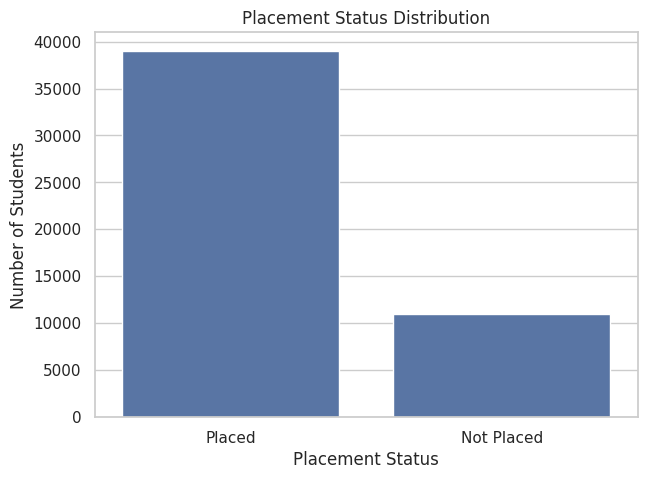

In [19]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="placement_status"
)

plt.title("Placement Status Distribution")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")

plt.show()

In [27]:
[col for col in df.columns if "coding" in col.lower() or "program" in col.lower()]

['programming_skill']

In [28]:
[col for col in df.columns if "coding" in col.lower() or "program" in col.lower()]

['programming_skill']

In [30]:
print(df.columns.tolist())

['student_id', 'age', 'gender', 'university_year', 'major', 'attendance_percentage', 'study_hours_per_week', 'cgpa', 'academic_performance', 'programming_skill', 'projects_completed', 'certifications', 'hackathons', 'github_profile', 'internships', 'leadership_experience', 'linkedin_profile', 'resume_score', 'communication_skills', 'teamwork', 'problem_solving', 'english_proficiency', 'interview_score', 'employability_score', 'placement_status', 'company_tier', 'career_field', 'placement_mode', 'starting_salary_usd']


In [31]:
df.head()

,student_id,age,gender,university_year,major,attendance_percentage,study_hours_per_week,cgpa,academic_performance,programming_skill,...,teamwork,problem_solving,english_proficiency,interview_score,employability_score,placement_status,company_tier,career_field,placement_mode,starting_salary_usd
0,ST000001,22,Male,Sophomore,Computer Science,86,21,3.28,Good,9,...,7,8,Advanced,72,231.70,Placed,Tier 1,Backend Developer,Campus Placement,72082
1,ST000002,20,Female,Freshman,Computer Science,64,18,2.53,Poor,6,...,6,5,Basic,59,157.45,Not Placed,No Company,Not Placed,Not Applicable,0
2,ST000003,23,Male,Senior,Information Technology,75,19,2.83,Average,8,...,8,7,Advanced,76,203.45,Placed,Tier 1,IT Support Engineer,Campus Placement,94898
3,ST000004,23,Female,Senior,Information Technology,80,19,2.80,Average,5,...,6,6,Intermediate,67,171.50,Not Placed,No Company,Not Placed,Not Applicable,0
4,ST000005,23,Female,Senior,Software Engineering,73,19,2.93,Average,9,...,8,9,Advanced,82,225.45,Placed,Tier 1,Software Engineer,Internship Conversion,85256


In [32]:
for col in df.columns:
    print(col)

student_id
age
gender
university_year
major
attendance_percentage
study_hours_per_week
cgpa
academic_performance
programming_skill
projects_completed
certifications
hackathons
github_profile
internships
leadership_experience
linkedin_profile
resume_score
communication_skills
teamwork
problem_solving
english_proficiency
interview_score
employability_score
placement_status
company_tier
career_field
placement_mode
starting_salary_usd


In [33]:
print("Coding-related columns:")
print([col for col in df.columns if
       any(word in col.lower() for word in
           ["coding", "code", "programming", "technical", "skill"])])

Coding-related columns:
['programming_skill', 'communication_skills']


In [34]:
print(df.columns.tolist())

['student_id', 'age', 'gender', 'university_year', 'major', 'attendance_percentage', 'study_hours_per_week', 'cgpa', 'academic_performance', 'programming_skill', 'projects_completed', 'certifications', 'hackathons', 'github_profile', 'internships', 'leadership_experience', 'linkedin_profile', 'resume_score', 'communication_skills', 'teamwork', 'problem_solving', 'english_proficiency', 'interview_score', 'employability_score', 'placement_status', 'company_tier', 'career_field', 'placement_mode', 'starting_salary_usd']


In [36]:
[col for col in df.columns if "intern" in col.lower()]

['internships']

In [37]:
df.groupby("placement_status")["internships"].mean()

,internships
placement_status,
Not Placed,3.304745
Placed,4.257787


In [38]:
pd.crosstab(
    df["internships"],
    df["placement_status"],
    normalize="index"
) * 100

placement_status,Not Placed,Placed
internships,,
0,93.220339,6.779661
1,76.038339,23.961661
2,59.272510,40.727490
3,38.102100,61.897900
4,19.871585,80.128415
5,8.130779,91.869221


In [39]:
[col for col in df.columns if "project" in col.lower()]

['projects_completed']

In [40]:
df.groupby("placement_status")["project_score"].mean()

KeyError: 'Column not found: project_score'

In [41]:
print("ALL COLUMNS IN YOUR DATASET:")
print(df.columns.tolist())

ALL COLUMNS IN YOUR DATASET:
['student_id', 'age', 'gender', 'university_year', 'major', 'attendance_percentage', 'study_hours_per_week', 'cgpa', 'academic_performance', 'programming_skill', 'projects_completed', 'certifications', 'hackathons', 'github_profile', 'internships', 'leadership_experience', 'linkedin_profile', 'resume_score', 'communication_skills', 'teamwork', 'problem_solving', 'english_proficiency', 'interview_score', 'employability_score', 'placement_status', 'company_tier', 'career_field', 'placement_mode', 'starting_salary_usd']


In [42]:
df.head()

,student_id,age,gender,university_year,major,attendance_percentage,study_hours_per_week,cgpa,academic_performance,programming_skill,...,teamwork,problem_solving,english_proficiency,interview_score,employability_score,placement_status,company_tier,career_field,placement_mode,starting_salary_usd
0,ST000001,22,Male,Sophomore,Computer Science,86,21,3.28,Good,9,...,7,8,Advanced,72,231.70,Placed,Tier 1,Backend Developer,Campus Placement,72082
1,ST000002,20,Female,Freshman,Computer Science,64,18,2.53,Poor,6,...,6,5,Basic,59,157.45,Not Placed,No Company,Not Placed,Not Applicable,0
2,ST000003,23,Male,Senior,Information Technology,75,19,2.83,Average,8,...,8,7,Advanced,76,203.45,Placed,Tier 1,IT Support Engineer,Campus Placement,94898
3,ST000004,23,Female,Senior,Information Technology,80,19,2.80,Average,5,...,6,6,Intermediate,67,171.50,Not Placed,No Company,Not Placed,Not Applicable,0
4,ST000005,23,Female,Senior,Software Engineering,73,19,2.93,Average,9,...,8,9,Advanced,82,225.45,Placed,Tier 1,Software Engineer,Internship Conversion,85256


In [43]:
for i, col in enumerate(df.columns):
    print(i, "→", col)

0 → student_id
1 → age
2 → gender
3 → university_year
4 → major
5 → attendance_percentage
6 → study_hours_per_week
7 → cgpa
8 → academic_performance
9 → programming_skill
10 → projects_completed
11 → certifications
12 → hackathons
13 → github_profile
14 → internships
15 → leadership_experience
16 → linkedin_profile
17 → resume_score
18 → communication_skills
19 → teamwork
20 → problem_solving
21 → english_proficiency
22 → interview_score
23 → employability_score
24 → placement_status
25 → company_tier
26 → career_field
27 → placement_mode
28 → starting_salary_usd
